# Real Estate Investment Advisor
## Step 2: Exploratory Data Analysis (EDA)
### Part 1: Price and Size Analysis (Questions 1–5)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/cleaned_housing_data.csv")
print(df.shape)

(250000, 36)


**Q1. What is the distribution of property prices?**

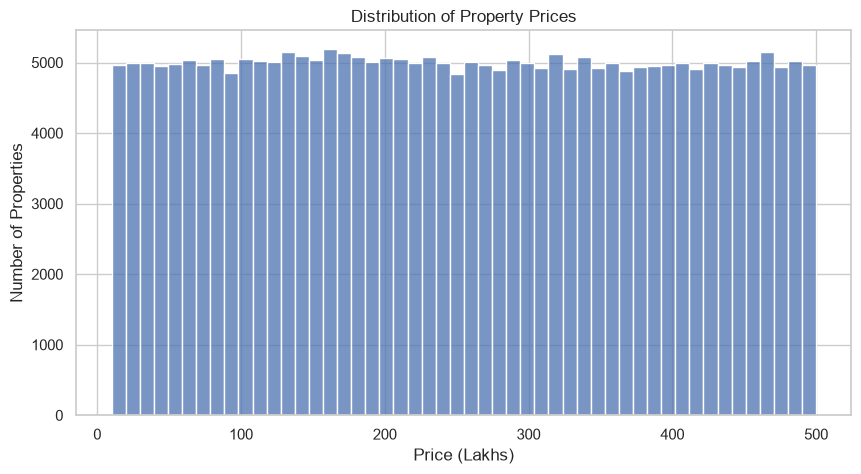

count    250000.00
mean        254.59
std         141.35
min          10.00
25%         132.55
50%         253.87
75%         376.88
max         500.00
Name: Price_in_Lakhs, dtype: float64
Skewness: 0.01


In [2]:
plt.figure(figsize=(10, 5))
sns.histplot(df["Price_in_Lakhs"], bins=50)
plt.title("Distribution of Property Prices")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Number of Properties")
plt.show()

print(df["Price_in_Lakhs"].describe().round(2))
print("Skewness:", round(df["Price_in_Lakhs"].skew(), 2))

*Figure 1: Distribution of property prices.*

Prices range from ₹10 lakhs to ₹500 lakhs, with a mean of ₹254.6 lakhs and a
median of ₹253.9 lakhs. The distribution is **almost perfectly uniform**
(skewness 0.01): every price range has about the same number of properties.
Real housing markets are usually right-skewed, with many affordable homes and
few expensive ones, so this flat shape suggests the data is synthetic.

**Q2. What is the distribution of property sizes?**

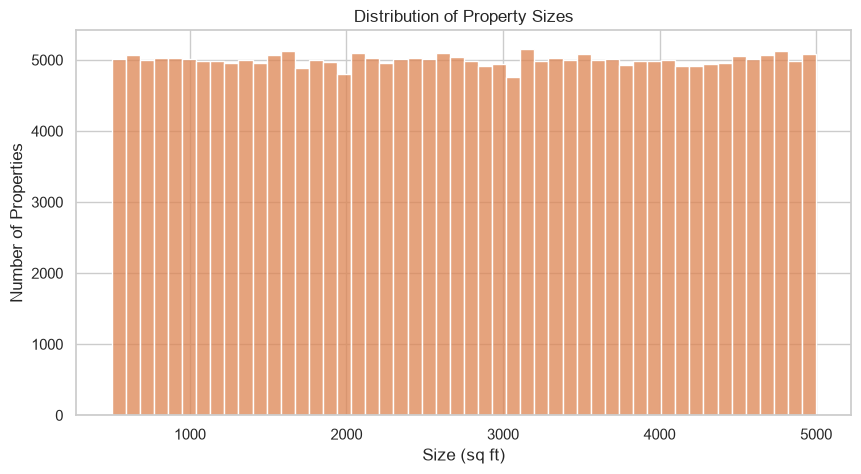

count    250000.00
mean       2749.81
std        1300.61
min         500.00
25%        1623.00
50%        2747.00
75%        3874.00
max        5000.00
Name: Size_in_SqFt, dtype: float64
Skewness: 0.0


In [3]:
plt.figure(figsize=(10, 5))
sns.histplot(df["Size_in_SqFt"], bins=50, color="#DD8452")
plt.title("Distribution of Property Sizes")
plt.xlabel("Size (sq ft)")
plt.ylabel("Number of Properties")
plt.show()

print(df["Size_in_SqFt"].describe().round(2))
print("Skewness:", round(df["Size_in_SqFt"].skew(), 2))

*Figure 2: Distribution of property sizes.*

Sizes range from 500 to 5,000 sq ft, with a median of 2,747 sq ft. Like price,
size is **uniformly distributed** (skewness 0.0), with no common size range.

**Q3. How does price per sq ft vary by property type?**

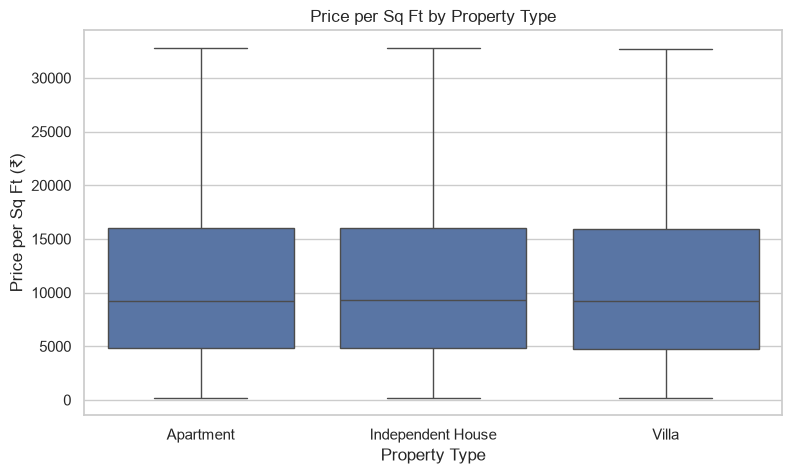

,mean,median
Property_Type,,
Apartment,13047.0,9245.0
Independent House,13102.0,9305.0
Villa,13026.0,9190.0


In [4]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Property_Type", y="Price_per_SqFt", showfliers=False)
plt.title("Price per Sq Ft by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Price per Sq Ft (₹)")
plt.show()

df.groupby("Property_Type")["Price_per_SqFt"].agg(["mean", "median"]).round(0)

*Figure 3: Price per sq ft by property type (outliers hidden for readability;
they are analysed in Q5).*

All three property types have nearly the same price per sq ft: a median of
about ₹9,200–9,300 and a mean of about ₹13,000. **Property type has almost no
effect** on price per sq ft in this dataset. The mean is much higher than the
median because a small number of properties have very high values per sq ft.

**Q4. Is there a relationship between property size and price?**

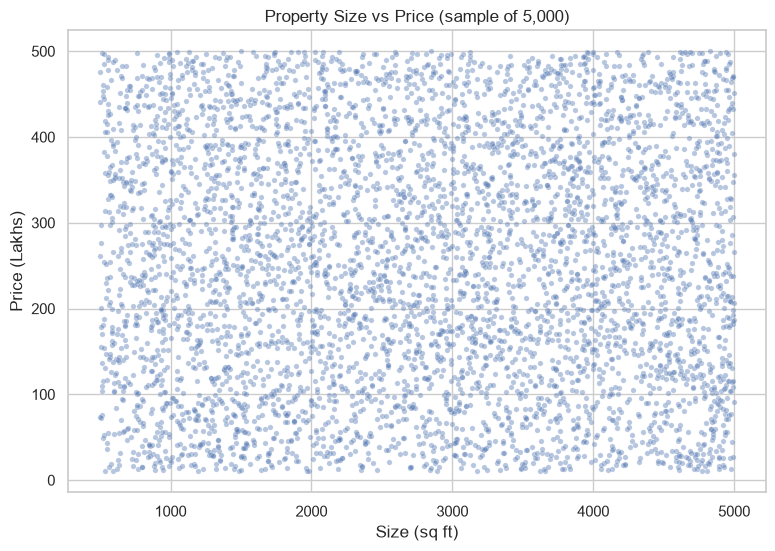

Correlation: -0.003


In [5]:
sample = df.sample(5000, random_state=42)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=0.4, s=15)
plt.title("Property Size vs Price (sample of 5,000)")
plt.xlabel("Size (sq ft)")
plt.ylabel("Price (Lakhs)")
plt.show()

print("Correlation:", round(df["Size_in_SqFt"].corr(df["Price_in_Lakhs"]), 3))

*Figure 4: Property size vs price for a random sample of 5,000 properties
(plotting all 250,000 points would be slow and unreadable).*

There is **no relationship** between size and price: the correlation is
−0.003, essentially zero. In a real market, larger homes cost more. This
confirms that price in this dataset was generated independently of size.

**Q5. Are there any outliers in price per sq ft or property size?**

Outliers are identified with the IQR method: values below Q1 − 1.5×IQR or
above Q3 + 1.5×IQR.

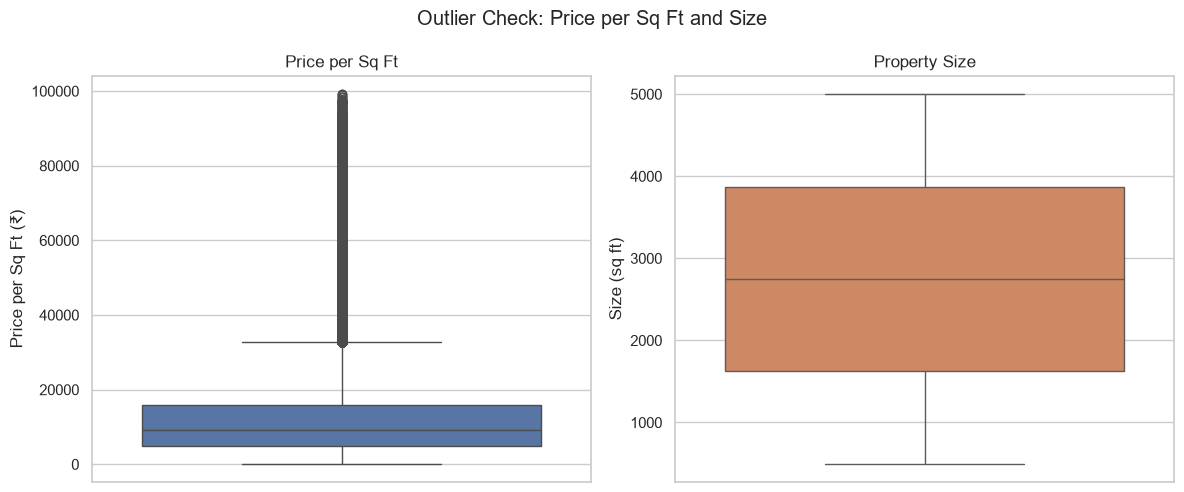

Price_per_SqFt: upper limit = 32,764.22, outliers = 19,723 (7.9%)
Size_in_SqFt: upper limit = 7,250.50, outliers = 0 (0.0%)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=df["Price_per_SqFt"], ax=axes[0])
axes[0].set_title("Price per Sq Ft")
axes[0].set_ylabel("Price per Sq Ft (₹)")
sns.boxplot(y=df["Size_in_SqFt"], ax=axes[1], color="#DD8452")
axes[1].set_title("Property Size")
axes[1].set_ylabel("Size (sq ft)")
plt.suptitle("Outlier Check: Price per Sq Ft and Size")
plt.tight_layout()
plt.show()

for col in ["Price_per_SqFt", "Size_in_SqFt"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: upper limit = {upper:,.2f}, outliers = {n:,} ({n / len(df):.1%})")

*Figure 5: Box plots of price per sq ft and property size.*

- **Size:** no outliers. All sizes fall between 500 and 5,000 sq ft.
- **Price per sq ft:** 19,723 properties (7.9%) are above ₹32,764 per sq ft,
  reaching up to ₹99,182. These are small properties with high prices, for
  example a 500 sq ft home priced at ₹495 lakhs.

**Decision: outliers are kept.** They are not data errors: each value is
correctly calculated from a valid price and a valid size. Dividing price by
size naturally creates a long right tail. Removing 7.9% of the data would
lose information, and the tree-based models used later are robust to outliers.

### Part 2: Location-based Analysis (Questions 6–10)

**Q6. What is the average price per sq ft by state?**

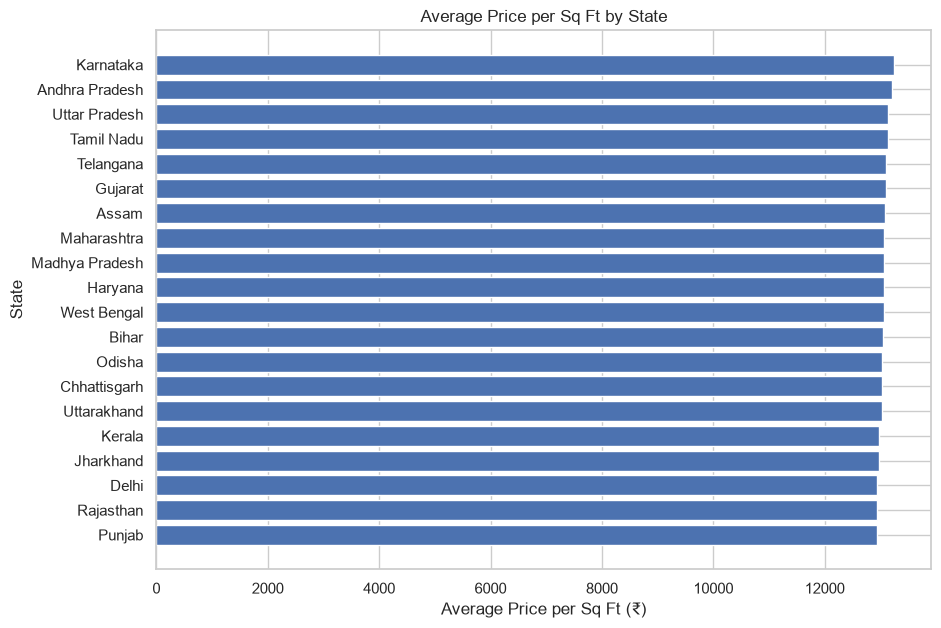

Highest: Karnataka (₹13,252)
Lowest: Punjab (₹12,931)
Difference: 2.5%


In [7]:
state_pps = df.groupby("State")["Price_per_SqFt"].mean().sort_values()

plt.figure(figsize=(10, 7))
plt.barh(state_pps.index, state_pps.values, color="#4C72B0")
plt.title("Average Price per Sq Ft by State")
plt.xlabel("Average Price per Sq Ft (₹)")
plt.ylabel("State")
plt.show()

print(f"Highest: {state_pps.index[-1]} (₹{state_pps.iloc[-1]:,.0f})")
print(f"Lowest: {state_pps.index[0]} (₹{state_pps.iloc[0]:,.0f})")
print(f"Difference: {(state_pps.max() / state_pps.min() - 1):.1%}")

*Figure 6: Average price per sq ft for each of the 20 states.*

Average price per sq ft is nearly the same in every state, ranging from
₹12,931 (Punjab) to ₹13,252 (Karnataka), a difference of only 2.5%.
**State has very little effect on price per sq ft.** In a real market,
states such as Maharashtra and Karnataka would be far more expensive than
smaller states, so this again points to synthetic data.

**Q7. What is the average property price by city?**

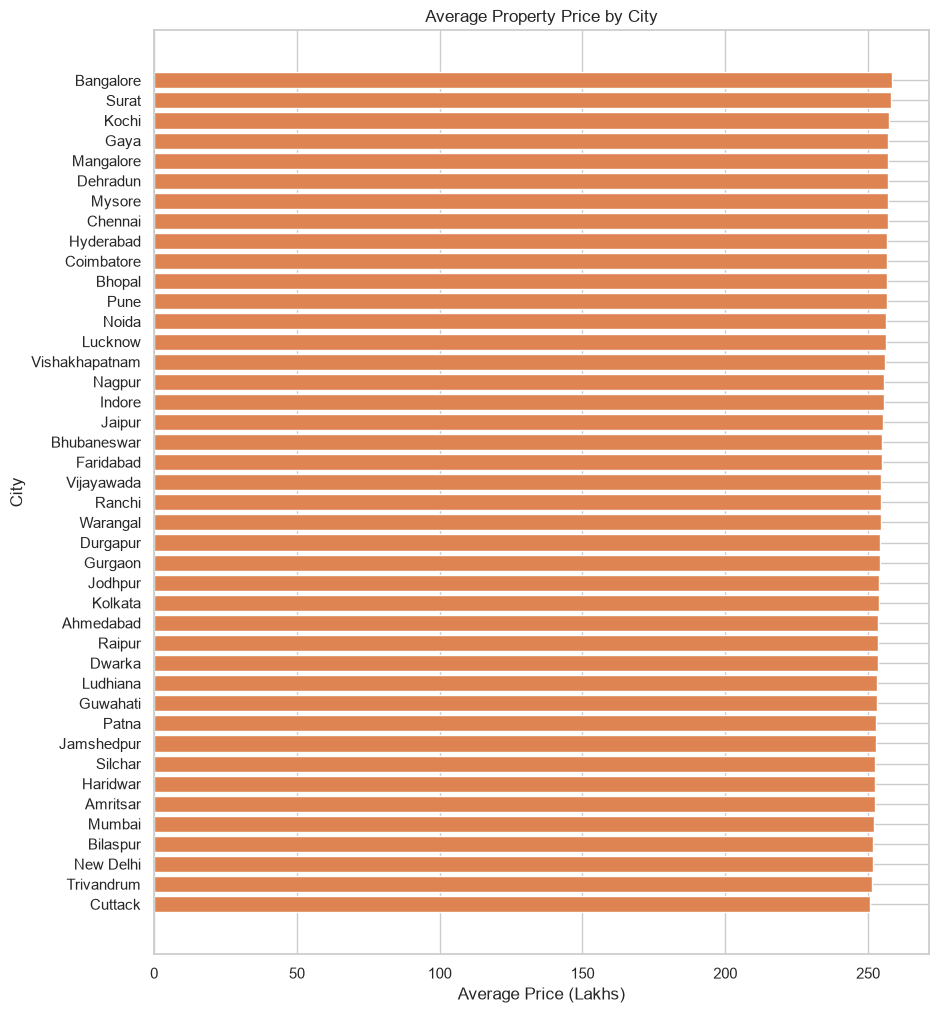

Highest: Bangalore (₹258.46 lakhs)
Lowest: Cuttack (₹250.79 lakhs)
Difference: 3.1%


In [8]:
city_price = df.groupby("City")["Price_in_Lakhs"].mean().sort_values()

plt.figure(figsize=(10, 12))
plt.barh(city_price.index, city_price.values, color="#DD8452")
plt.title("Average Property Price by City")
plt.xlabel("Average Price (Lakhs)")
plt.ylabel("City")
plt.show()

print(f"Highest: {city_price.index[-1]} (₹{city_price.iloc[-1]:.2f} lakhs)")
print(f"Lowest: {city_price.index[0]} (₹{city_price.iloc[0]:.2f} lakhs)")
print(f"Difference: {(city_price.max() / city_price.min() - 1):.1%}")

*Figure 7: Average property price for each of the 42 cities.*

Average prices range from ₹250.79 lakhs (Cuttack) to ₹258.46 lakhs
(Bangalore), a difference of only 3.1%. Bangalore ranks highest, which
matches real-world expectations, but the gap is too small to be meaningful:
**city has almost no effect on property price** in this dataset.

**Q8. What is the median age of properties by locality?**

Cities each locality name appears in: 42.0


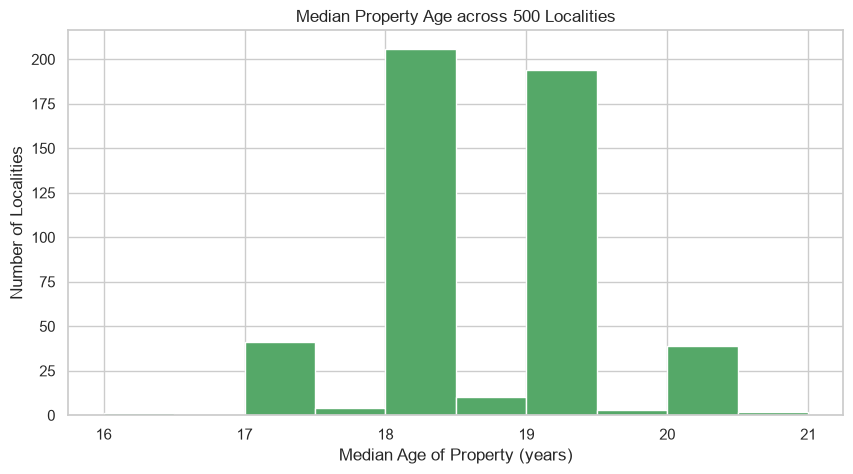

count    500.00
mean      18.48
std        0.78
min       16.00
25%       18.00
50%       18.00
75%       19.00
max       21.00
Name: Age_of_Property, dtype: float64


In [9]:
print("Cities each locality name appears in:",
      df.groupby("Locality")["City"].nunique().median())

loc_age = df.groupby("Locality")["Age_of_Property"].median()

plt.figure(figsize=(10, 5))
plt.hist(loc_age, bins=10, color="#55A868", edgecolor="white")
plt.title("Median Property Age across 500 Localities")
plt.xlabel("Median Age of Property (years)")
plt.ylabel("Number of Localities")
plt.show()

print(loc_age.describe().round(2))

*Figure 8: Distribution of median property age across the 500 localities.*

There are 500 locality names, so a histogram of their median ages is shown
instead of 500 separate bars. Median ages fall in a narrow range of **16 to
21 years**, and most localities have a median age of 18 or 19 years. No
locality stands out as especially old or new.

**Note:** each locality name (for example "Locality_84") appears in all 42
cities, so it does not represent one real neighbourhood. Grouping by locality
name combines properties from different cities, which also helps explain why
the medians are so similar.

**Q9. How is BHK distributed across cities?**

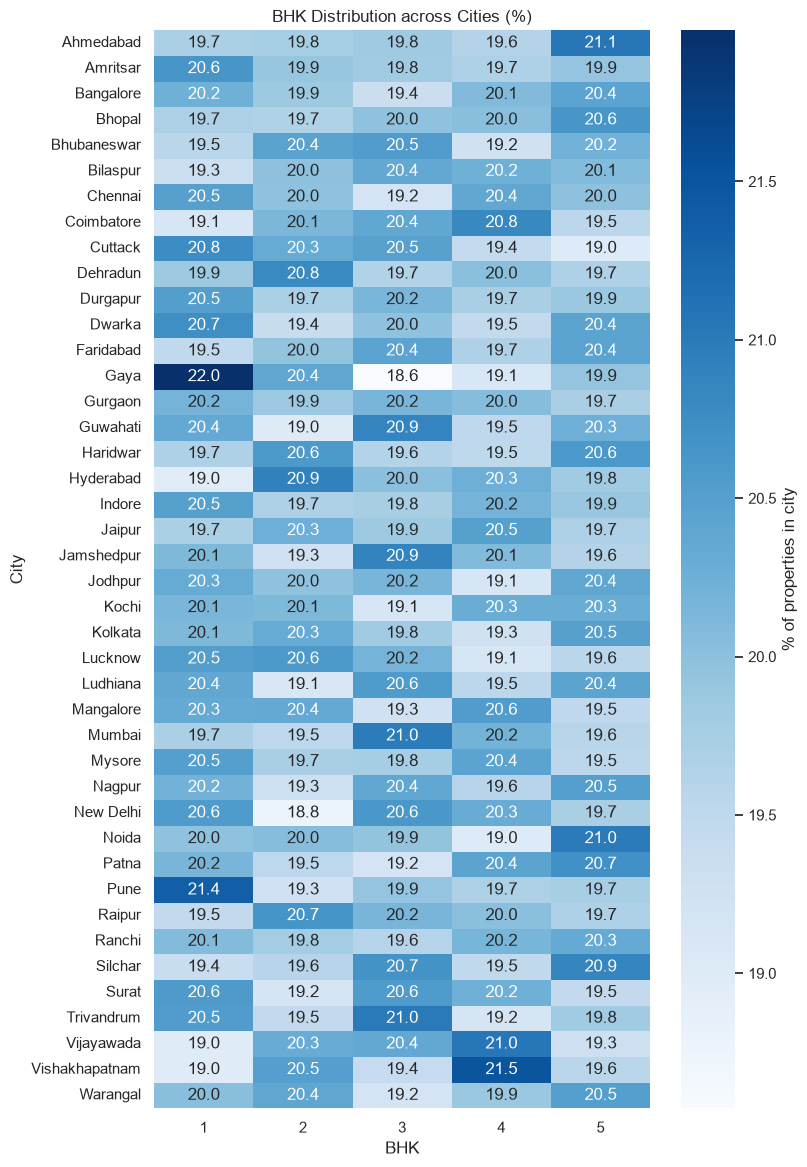

BHK share per city ranges from 18.6% to 22.0%


In [10]:
bhk_city = pd.crosstab(df["City"], df["BHK"], normalize="index").mul(100)

plt.figure(figsize=(8, 14))
sns.heatmap(bhk_city, annot=True, fmt=".1f", cmap="Blues",
            cbar_kws={"label": "% of properties in city"})
plt.title("BHK Distribution across Cities (%)")
plt.xlabel("BHK")
plt.ylabel("City")
plt.show()

print(f"BHK share per city ranges from {bhk_city.values.min():.1f}% "
      f"to {bhk_city.values.max():.1f}%")

*Figure 9: Percentage of properties with each BHK count, by city.*

In every city, each BHK type (1 to 5) makes up about **20%** of properties,
with shares between 18.6% and 22.0%. BHK is **evenly distributed** across all
cities. In reality, 2 and 3 BHK homes usually dominate, and large cities have
more small units, so this equal split is another sign of synthetic data.

**Q10. What are the price trends for the top 5 most expensive localities?**

The dataset has no sale dates, so the trend is shown across the period each
property was built (Year_Built), grouped into periods of about five years.

Locality
Locality_395    275.43
Locality_366    273.41
Locality_497    270.00
Locality_360    269.81
Locality_203    269.03
Name: Price_in_Lakhs, dtype: float64


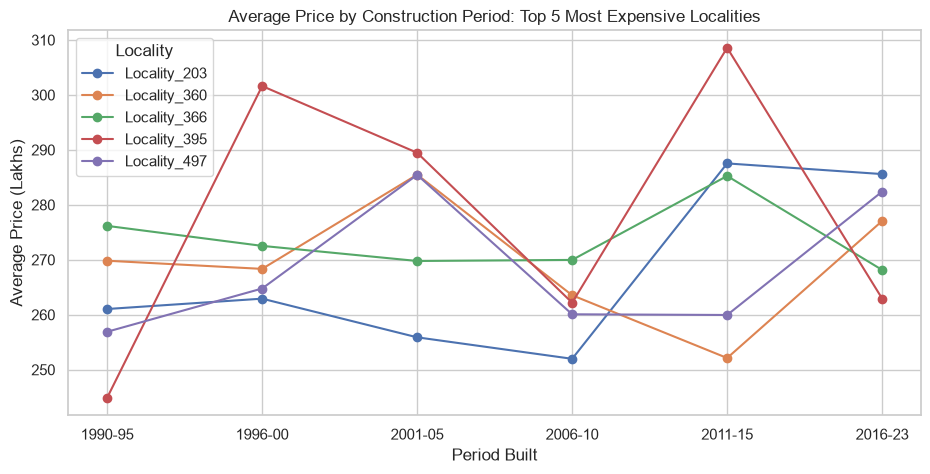

In [11]:
top5 = df.groupby("Locality")["Price_in_Lakhs"].mean().nlargest(5)
print(top5.round(2))

top_df = df[df["Locality"].isin(top5.index)].copy()
top_df["Built_Period"] = pd.cut(top_df["Year_Built"],
                                bins=[1989, 1995, 2000, 2005, 2010, 2015, 2023],
                                labels=["1990-95", "1996-00", "2001-05",
                                        "2006-10", "2011-15", "2016-23"])
trend = (top_df.groupby(["Built_Period", "Locality"], observed=True)["Price_in_Lakhs"]
               .mean().unstack())

trend.plot(marker="o", figsize=(11, 5))
plt.title("Average Price by Construction Period: Top 5 Most Expensive Localities")
plt.xlabel("Period Built")
plt.ylabel("Average Price (Lakhs)")
plt.legend(title="Locality")
plt.show()

*Figure 10: Average price by construction period for the five localities with
the highest average prices.*

The five most expensive localities have average prices of ₹269–275 lakhs,
only about 6–8% above the overall average of ₹254.6 lakhs. Across
construction periods, their prices **rise and fall without a consistent
trend**, between about ₹245 and ₹309 lakhs. Each locality has only about
460–530 properties, split into six periods, so these swings are mainly random
variation rather than real price trends.

### Part 3: Feature Relationships and Correlation (Questions 11–15)

**Q11. How are numeric features correlated with each other?**

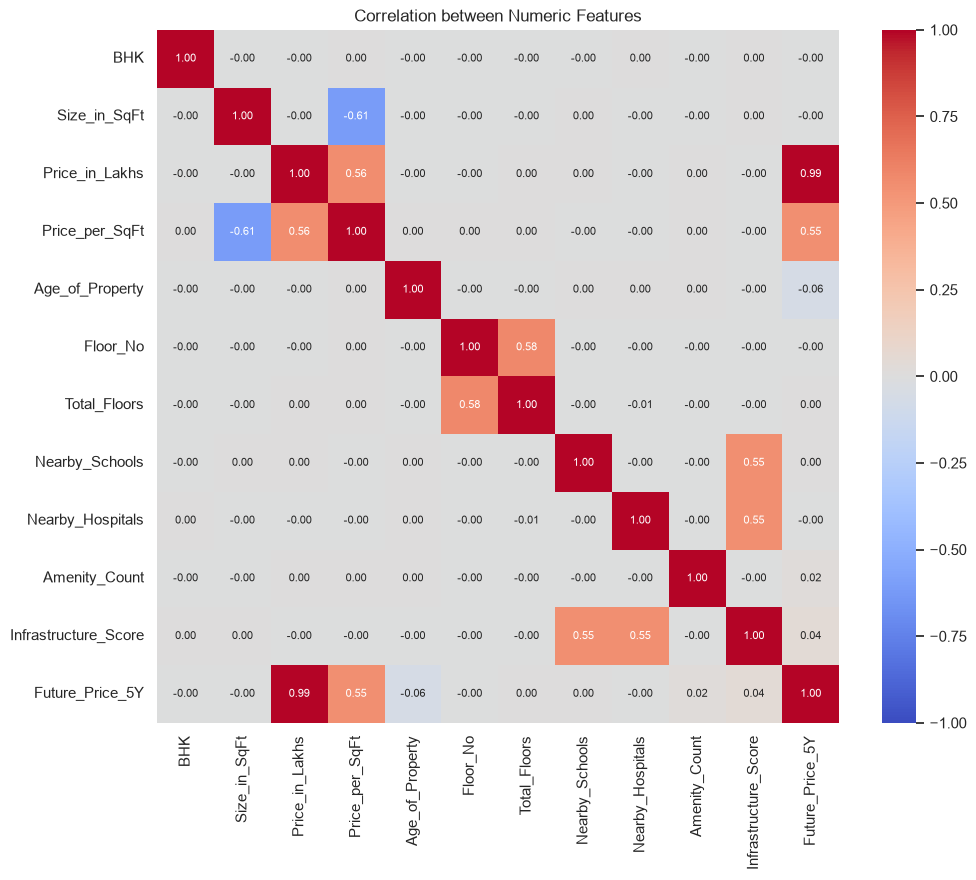

Price_in_Lakhs    Future_Price_5Y         0.99
Size_in_SqFt      Price_per_SqFt         -0.61
Floor_No          Total_Floors            0.58
Price_in_Lakhs    Price_per_SqFt          0.56
Price_per_SqFt    Future_Price_5Y         0.55
Nearby_Schools    Infrastructure_Score    0.55
Nearby_Hospitals  Infrastructure_Score    0.55
dtype: float64


In [12]:
num_cols = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt",
            "Age_of_Property", "Floor_No", "Total_Floors", "Nearby_Schools",
            "Nearby_Hospitals", "Amenity_Count", "Infrastructure_Score",
            "Future_Price_5Y"]
corr = df[num_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Correlation between Numeric Features")
plt.show()

# List the pairs with a correlation stronger than 0.1 (positive or negative)
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
strong = pairs[pairs.abs() > 0.1].sort_values(key=abs, ascending=False)
print(strong.round(2))

*Figure 11: Correlation matrix of numeric features (1 = perfect positive,
−1 = perfect negative, 0 = no relationship).*

Only seven pairs have a correlation stronger than 0.1, and **every one of
them is explained by how the columns were calculated**, not by market
behaviour:
- **Price and Future Price (0.99):** future price was calculated from current
  price.
- **Price per sq ft with Size (−0.61) and Price (0.56):** price per sq ft is
  price divided by size.
- **Floor_No and Total_Floors (0.58):** floor numbers were capped at the
  building's total floors during cleaning.
- **Schools and Hospitals with Infrastructure Score (0.55 each):** the score
  is built from these columns.

All other features, including BHK, size, age and amenities, are essentially
**uncorrelated** with each other and with price. This tells us that no single
feature drives price in this dataset.

**Q12. How do nearby schools relate to price per sq ft?**

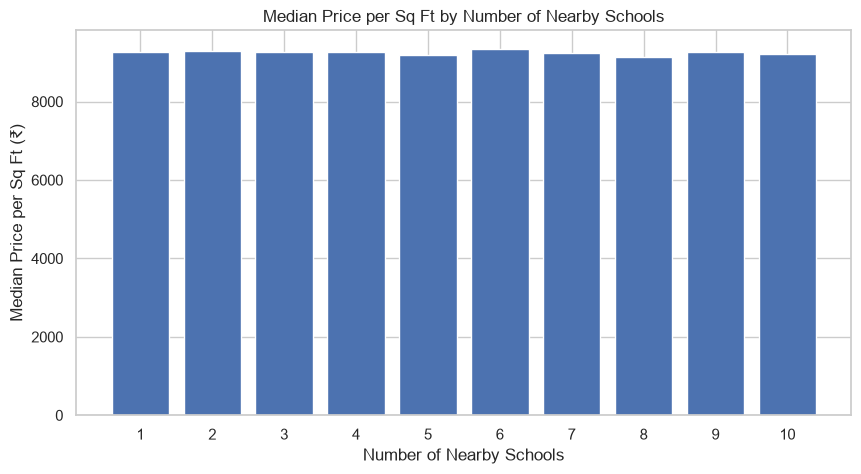

Median range: ₹9,144 to ₹9,352
Correlation: -0.0001


In [13]:
school_pps = df.groupby("Nearby_Schools")["Price_per_SqFt"].median()

plt.figure(figsize=(10, 5))
plt.bar(school_pps.index, school_pps.values, color="#4C72B0")
plt.title("Median Price per Sq Ft by Number of Nearby Schools")
plt.xlabel("Number of Nearby Schools")
plt.ylabel("Median Price per Sq Ft (₹)")
plt.xticks(range(1, 11))
plt.show()

print(f"Median range: ₹{school_pps.min():,.0f} to ₹{school_pps.max():,.0f}")
print(f"Correlation: {df['Nearby_Schools'].corr(df['Price_per_SqFt']):.4f}")

*Figure 12: Median price per sq ft for properties with 1 to 10 nearby schools.
The median is used because price per sq ft has outliers (see Q5).*

Median price per sq ft stays between ₹9,144 and ₹9,352 regardless of how many
schools are nearby, and the correlation is effectively zero (−0.0001).
**Nearby schools do not affect price per sq ft** in this dataset. In a real
market, homes near good schools usually sell at a premium.

**Q13. How do nearby hospitals relate to price per sq ft?**

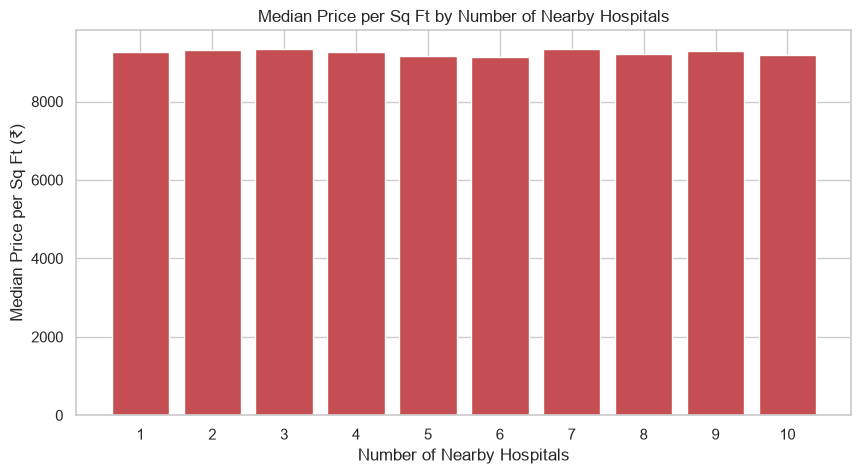

Median range: ₹9,129 to ₹9,349
Correlation: -0.0001


In [14]:
hosp_pps = df.groupby("Nearby_Hospitals")["Price_per_SqFt"].median()

plt.figure(figsize=(10, 5))
plt.bar(hosp_pps.index, hosp_pps.values, color="#C44E52")
plt.title("Median Price per Sq Ft by Number of Nearby Hospitals")
plt.xlabel("Number of Nearby Hospitals")
plt.ylabel("Median Price per Sq Ft (₹)")
plt.xticks(range(1, 11))
plt.show()

print(f"Median range: ₹{hosp_pps.min():,.0f} to ₹{hosp_pps.max():,.0f}")
print(f"Correlation: {df['Nearby_Hospitals'].corr(df['Price_per_SqFt']):.4f}")

*Figure 13: Median price per sq ft for properties with 1 to 10 nearby
hospitals.*

As with schools, median price per sq ft stays in a narrow band (₹9,129 to
₹9,349), and the correlation is effectively zero. **The number of nearby
hospitals has no effect on price per sq ft.**

**Q14. How does price vary by furnished status?**

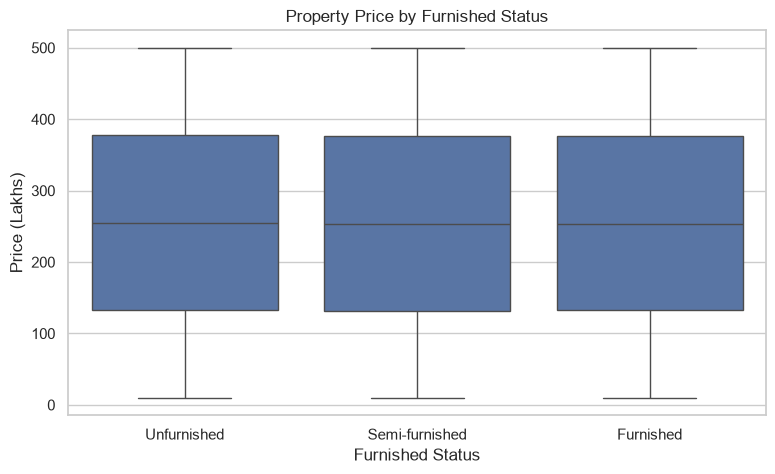

,mean,median
Furnished_Status,,
Furnished,254.45,253.56
Semi-furnished,254.33,253.81
Unfurnished,254.98,254.19


In [15]:
order = ["Unfurnished", "Semi-furnished", "Furnished"]

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Furnished_Status", y="Price_in_Lakhs", order=order)
plt.title("Property Price by Furnished Status")
plt.xlabel("Furnished Status")
plt.ylabel("Price (Lakhs)")
plt.show()

df.groupby("Furnished_Status")["Price_in_Lakhs"].agg(["mean", "median"]).round(2)

*Figure 14: Property price by furnished status.*

Average prices are almost identical, about ₹254–255 lakhs for all three
types. Unfurnished properties are even very slightly higher on average
(₹254.98 lakhs vs ₹254.45 lakhs for furnished). **Furnishing does not affect
price** in this dataset, whereas in reality furnished homes usually cost more.

**Q15. How does price per sq ft vary by property facing direction?**

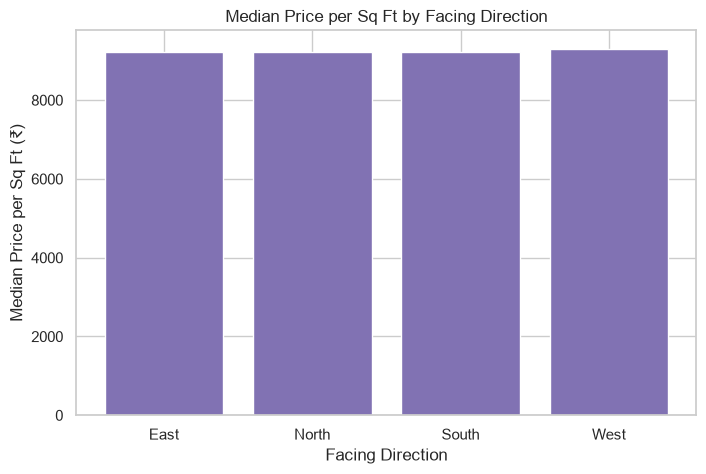

,mean,median
Facing,,
East,13024.0,9234.0
North,13025.0,9219.0
South,13044.0,9225.0
West,13140.0,9308.0


In [16]:
facing = df.groupby("Facing")["Price_per_SqFt"].agg(["mean", "median"])

plt.figure(figsize=(8, 5))
plt.bar(facing.index, facing["median"], color="#8172B3")
plt.title("Median Price per Sq Ft by Facing Direction")
plt.xlabel("Facing Direction")
plt.ylabel("Median Price per Sq Ft (₹)")
plt.show()

facing.round(0)

*Figure 15: Median price per sq ft by the direction the property faces.*

West-facing properties have a slightly higher median price per sq ft
(₹9,308) than the others (about ₹9,220–9,235), but the difference is under
1%. **Facing direction has no meaningful effect on price.** In Indian markets,
east- and north-facing homes are often preferred (for example, due to Vastu),
so a real dataset might show a premium for those directions.

### Part 4: Investment, Amenities and Ownership Analysis (Questions 16–20)

**Q16. How many properties belong to each owner type?**

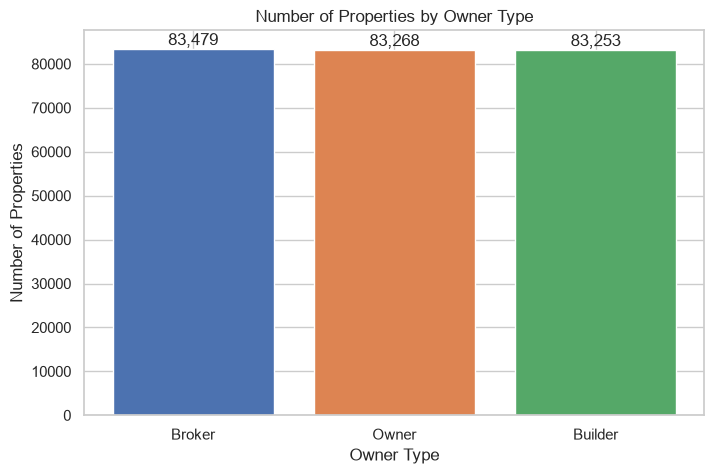

Owner_Type
Broker     33.4
Owner      33.3
Builder    33.3
Name: proportion, dtype: float64


In [17]:
owner = df["Owner_Type"].value_counts()

plt.figure(figsize=(8, 5))
bars = plt.bar(owner.index, owner.values, color=["#4C72B0", "#DD8452", "#55A868"])
plt.bar_label(bars, fmt="{:,.0f}")
plt.title("Number of Properties by Owner Type")
plt.xlabel("Owner Type")
plt.ylabel("Number of Properties")
plt.show()

print(df["Owner_Type"].value_counts(normalize=True).mul(100).round(1))

*Figure 16: Number of properties listed by each owner type.*

Properties are split almost exactly equally between brokers (83,479),
owners (83,268) and builders (83,253), about **one-third each**. No owner
type dominates the listings.

**Q17. How many properties are available under each availability status?**

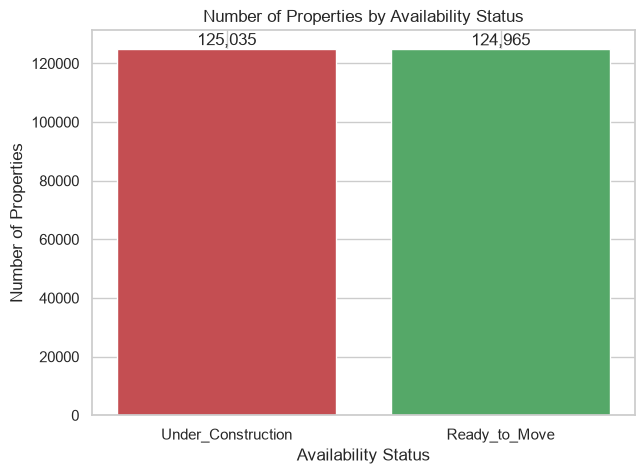

Availability_Status
Under_Construction    50.0
Ready_to_Move         50.0
Name: proportion, dtype: float64


In [18]:
avail = df["Availability_Status"].value_counts()

plt.figure(figsize=(7, 5))
bars = plt.bar(avail.index, avail.values, color=["#C44E52", "#55A868"])
plt.bar_label(bars, fmt="{:,.0f}")
plt.title("Number of Properties by Availability Status")
plt.xlabel("Availability Status")
plt.ylabel("Number of Properties")
plt.show()

print(df["Availability_Status"].value_counts(normalize=True).mul(100).round(1))

*Figure 17: Number of properties by availability status.*

The dataset contains only two statuses: **Under Construction (125,035)** and
**Ready to Move (124,965)**, an exact 50/50 split. The "Sold" status mentioned
in the dataset description does not appear in the data.

**Q18. Does parking space affect property price?**

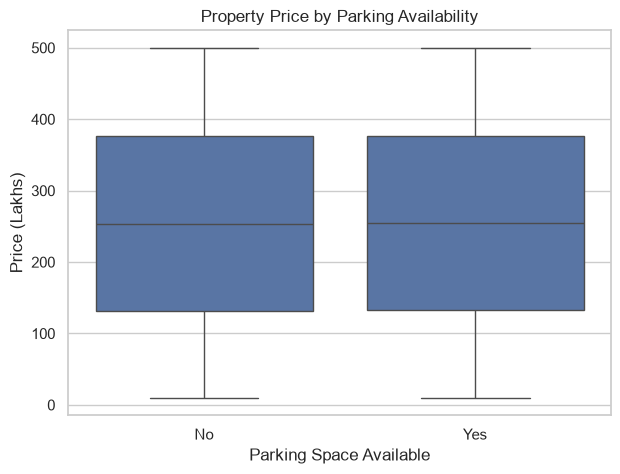

,mean,median
Parking_Space,,
No,254.43,253.37
Yes,254.75,254.36


In [19]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Parking_Space", y="Price_in_Lakhs", order=["No", "Yes"])
plt.title("Property Price by Parking Availability")
plt.xlabel("Parking Space Available")
plt.ylabel("Price (Lakhs)")
plt.show()

df.groupby("Parking_Space")["Price_in_Lakhs"].agg(["mean", "median"]).round(2)

*Figure 18: Property price for properties with and without parking.*

Properties with parking have an average price of ₹254.75 lakhs, compared
with ₹254.43 lakhs without, a difference of only ₹0.32 lakhs (about 0.1%).
**Parking has no meaningful effect on price** in this dataset.

**Q19. How do amenities affect price per sq ft?**

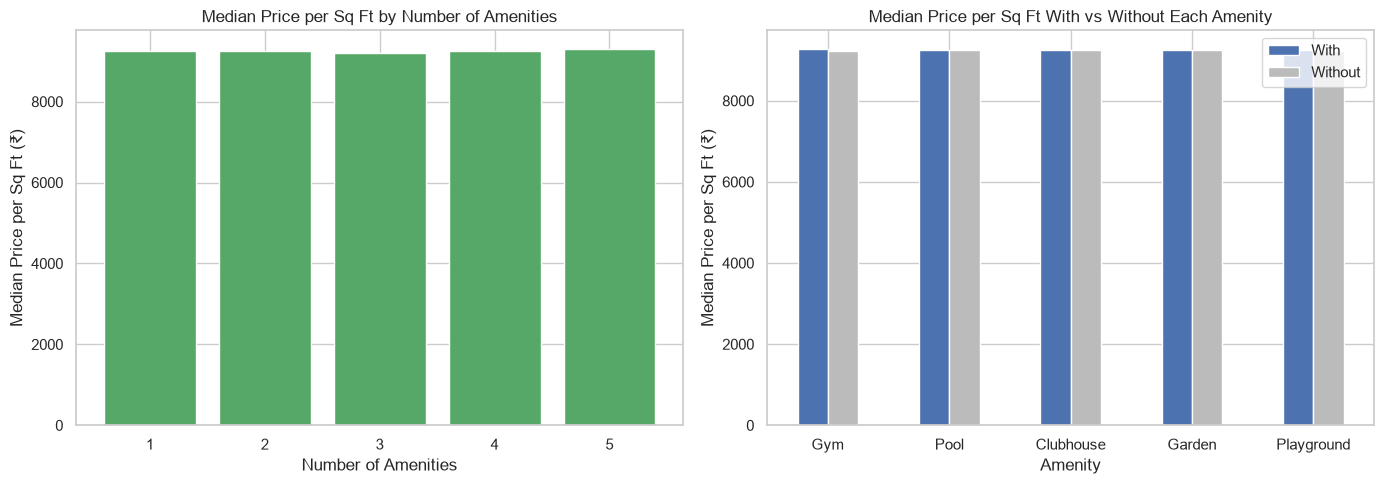

Amenity_Count
1    9240.0
2    9242.0
3    9207.0
4    9250.0
5    9294.0
Name: Price_per_SqFt, dtype: float64


,With,Without
Gym,9269.0,9223.0
Pool,9249.0,9241.0
Clubhouse,9242.0,9250.0
Garden,9247.0,9242.0
Playground,9260.0,9229.0


In [20]:
amenities = ["Gym", "Pool", "Clubhouse", "Garden", "Playground"]
amen_effect = pd.DataFrame({
    "With": [df[df[f"Has_{a}"] == 1]["Price_per_SqFt"].median() for a in amenities],
    "Without": [df[df[f"Has_{a}"] == 0]["Price_per_SqFt"].median() for a in amenities],
}, index=amenities)
count_pps = df.groupby("Amenity_Count")["Price_per_SqFt"].median()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(count_pps.index, count_pps.values, color="#55A868")
axes[0].set_title("Median Price per Sq Ft by Number of Amenities")
axes[0].set_xlabel("Number of Amenities")
axes[0].set_ylabel("Median Price per Sq Ft (₹)")

amen_effect.plot(kind="bar", ax=axes[1], color=["#4C72B0", "#BBBBBB"], rot=0)
axes[1].set_title("Median Price per Sq Ft With vs Without Each Amenity")
axes[1].set_xlabel("Amenity")
axes[1].set_ylabel("Median Price per Sq Ft (₹)")
plt.tight_layout()
plt.show()

print(count_pps.round(0))
amen_effect.round(0)

*Figure 19: Left: median price per sq ft by number of amenities. Right:
median price per sq ft for properties with and without each amenity.*

Median price per sq ft stays around ₹9,200–9,300 whether a property has one
amenity or five. For individual amenities, the difference between "with" and
"without" is under ₹50 per sq ft (less than 0.5%), and properties with a
clubhouse are even slightly cheaper. **Amenities do not affect price per sq
ft** in this dataset.

**Q20. How does public transport accessibility relate to price per sq ft or
investment potential?**

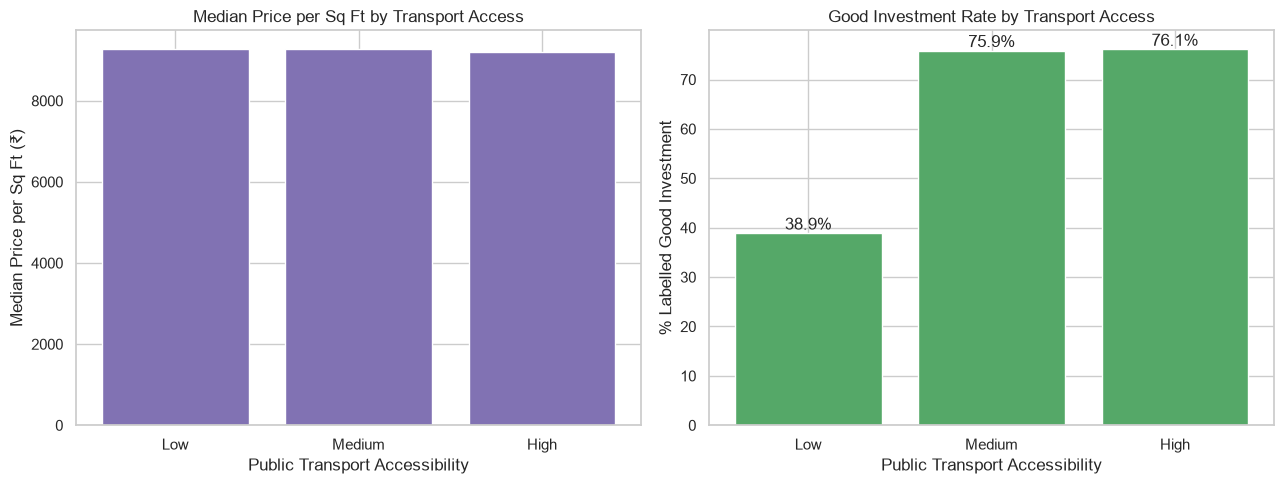

,Median_PPS,Good_Investment_Rate,Avg_Growth_Rate
Public_Transport_Accessibility,,,
Low,9265.3,38.9,7.4
Medium,9269.3,75.9,8.4
High,9205.1,76.1,9.4


In [21]:
order = ["Low", "Medium", "High"]
transport = (df.groupby("Public_Transport_Accessibility")
               .agg(Median_PPS=("Price_per_SqFt", "median"),
                    Good_Investment_Rate=("Good_Investment", "mean"),
                    Avg_Growth_Rate=("Growth_Rate", "mean"))
               .loc[order])
transport["Good_Investment_Rate"] *= 100
transport["Avg_Growth_Rate"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(order, transport["Median_PPS"], color="#8172B3")
axes[0].set_title("Median Price per Sq Ft by Transport Access")
axes[0].set_xlabel("Public Transport Accessibility")
axes[0].set_ylabel("Median Price per Sq Ft (₹)")

bars = axes[1].bar(order, transport["Good_Investment_Rate"], color="#55A868")
axes[1].bar_label(bars, fmt="%.1f%%")
axes[1].set_title("Good Investment Rate by Transport Access")
axes[1].set_xlabel("Public Transport Accessibility")
axes[1].set_ylabel("% Labelled Good Investment")
plt.tight_layout()
plt.show()

transport.round(1)

*Figure 20: Left: median price per sq ft by public transport access. Right:
percentage of properties labelled Good Investment.*

- **Price per sq ft:** transport access has no effect on current price.
  Median price per sq ft is about ₹9,200–9,270 for all three levels.
- **Investment potential:** properties with Medium or High access are about
  **twice as likely** to be labelled Good Investment (76%) as those with Low
  access (39%), and their expected yearly growth rate is higher (9.4% for
  High vs 7.4% for Low).

**Important:** these investment differences come from the rules used to
create the targets in Step 1. Transport access is one of the five Good
Investment conditions and adjusts the growth rate. The chart confirms the
targets were built as intended, but it is not independent evidence from the
market.

### EDA Summary

1. **Price and size are uniformly distributed** and unrelated to each other
   (correlation −0.003). Price per sq ft is right-skewed, with 7.9% outliers
   that were kept as valid values.
2. **Location has almost no effect:** average prices differ by only 2.5%
   across states and 3.1% across cities. Locality names repeat across all
   cities, so they do not identify real neighbourhoods.
3. **Property features do not drive price:** property type, BHK, furnishing,
   facing, parking, amenities, schools and hospitals all show near-zero
   relationships with price or price per sq ft.
4. **Categories are evenly balanced:** owner types, availability statuses and
   BHK counts are split almost equally in every city.
5. **Strong correlations exist only between calculated columns**, such as
   price and future price.

**Conclusion:** the dataset is synthetic, with features generated
independently of price. Real market patterns cannot be learned from it, which
is why both targets were created from documented, domain-based rules. The
models in the next step will learn these rules, so high accuracy is expected
and will be interpreted with this in mind.